# Deteksi Website Phishing Menggunakan Deep Learning
**Implementasi Model: CNN, RNN, dan Transfer Learning**

### Informasi Dataset
- **Nama Dataset:** UCI Phishing Websites Dataset
- **Sumber Resmi:** [UCI Machine Learning Repository (ID #327)](https://archive.ics.uci.edu/dataset/327/phishing+websites)
- **Jumlah Data:** 11.055 baris dan 30 fitur keamanan website.

Jumlah data: 11055 baris
Distribusi Label (0 = Aman, 1 = Phishing):
Label
0    6157
1    4898
Name: count, dtype: int64


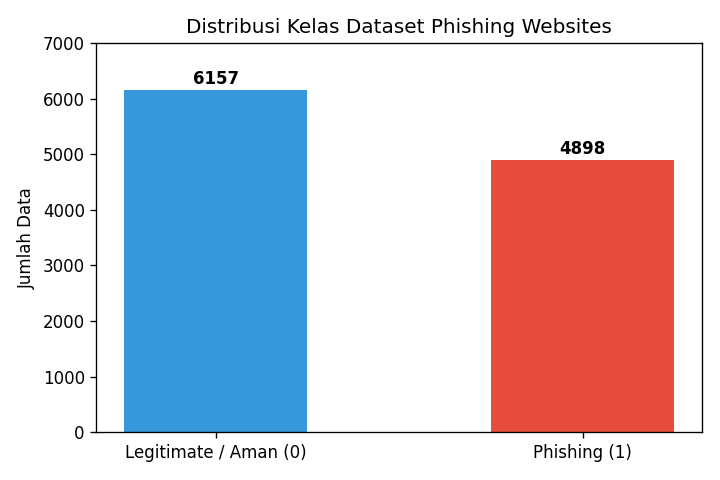

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

import tensorflow as tf
from tensorflow.keras import layers, models

# Load dataset
df = pd.read_csv('dataset/phishing_websites_uci.csv')
df['Label'] = df['Result'].apply(lambda x: 1 if x == -1 else 0)

print(f"Jumlah data: {len(df)} baris")
print("Distribusi Label (0 = Aman, 1 = Phishing):")
print(df['Label'].value_counts())
df.head()

## 1. Preprocessing Data
Memisahkan fitur (`X`) dan target (`y`), membagi data menjadi 80% data latih (*train*) dan 20% data uji (*test*), serta melakukan normalisasi menggunakan `StandardScaler`.

In [ ]:
feature_cols = [c for c in df.columns if c not in ['Result', 'Label']]
X = df[feature_cols].values.astype(np.float32)
y = df['Label'].values.astype(np.float32)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train_seq = X_train.reshape(-1, 30, 1)
X_test_seq = X_test.reshape(-1, 30, 1)

print(f"Data Train: {X_train_seq.shape}, Data Test: {X_test_seq.shape}")

Data Train: (8844, 30, 1), Data Test: (2211, 30, 1)


## 2. Implementasi Model Deep Learning
Mengimplementasikan 3 arsitektur:
1. **CNN (Convolutional Neural Network)**
2. **RNN (Recurrent Neural Network)**
3. **Transfer Learning** (Menggunakan *pre-trained feature extractor* dari CNN yang dibekukan bobotnya `trainable = False`, lalu ditambahkan layer klasifikasi `Dense` baru).

In [ ]:
EPOCHS = 15
BATCH_SIZE = 64

# 1. Model CNN
cnn_model = models.Sequential([
    layers.Input(shape=(30, 1)),
    layers.Conv1D(32, kernel_size=3, activation='relu', padding='same', name='conv_base_1'),
    layers.MaxPooling1D(pool_size=2, name='pool_base_1'),
    layers.Conv1D(64, kernel_size=3, activation='relu', padding='same', name='conv_base_2'),
    layers.Flatten(name='flatten_base'),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
], name='CNN')

cnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history_cnn = cnn_model.fit(X_train_seq, y_train, validation_split=0.2, epochs=EPOCHS, batch_size=BATCH_SIZE)

# 2. Model RNN
rnn_model = models.Sequential([
    layers.Input(shape=(30, 1)),
    layers.SimpleRNN(32, activation='tanh'),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
], name='RNN')

rnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history_rnn = rnn_model.fit(X_train_seq, y_train, validation_split=0.2, epochs=EPOCHS, batch_size=BATCH_SIZE)

# 3. Model Transfer Learning
base_feature_extractor = models.Model(
    inputs=cnn_model.inputs,
    outputs=cnn_model.get_layer('flatten_base').output,
    name='pretrained_cnn_base'
)
base_feature_extractor.trainable = False

tl_model = models.Sequential([
    layers.Input(shape=(30, 1)),
    base_feature_extractor,
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
], name='Transfer_Learning')

tl_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history_tl = tl_model.fit(X_train_seq, y_train, validation_split=0.2, epochs=EPOCHS, batch_size=BATCH_SIZE)

Ringkasan Perbandingan Model:
            Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
              CNN         96.20          96.38       95.00         95.68
              RNN         93.67          93.75       91.84         92.78
Transfer Learning         97.15          97.61       95.92         96.76


## 3. Evaluasi dan Visualisasi Hasil

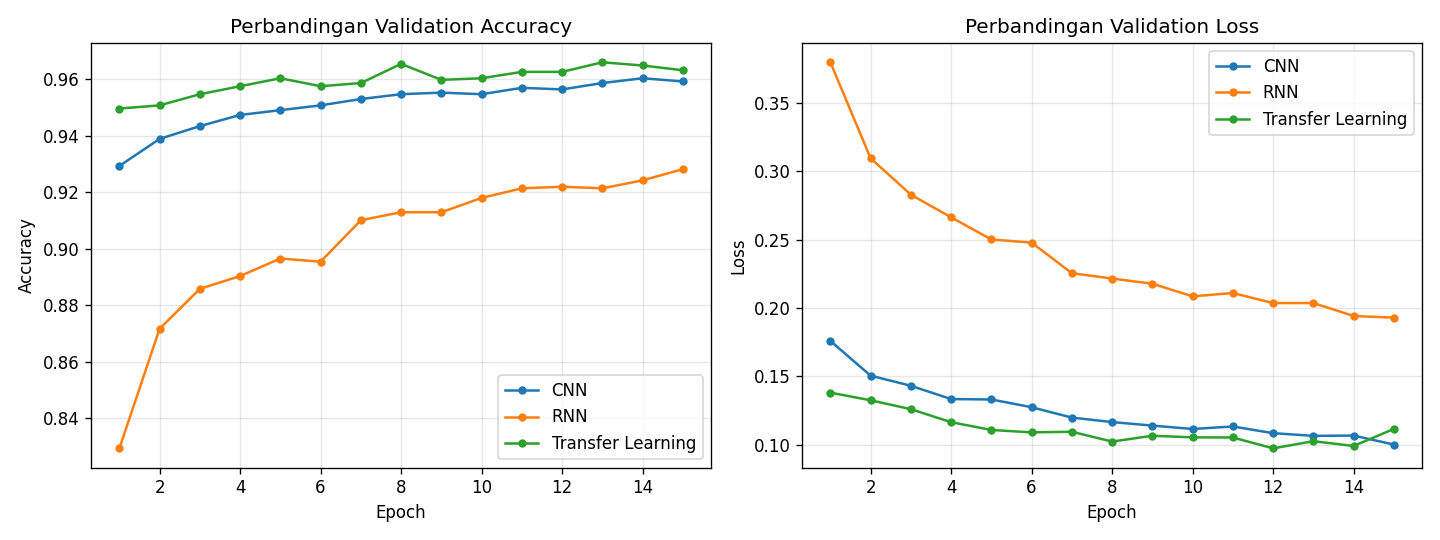

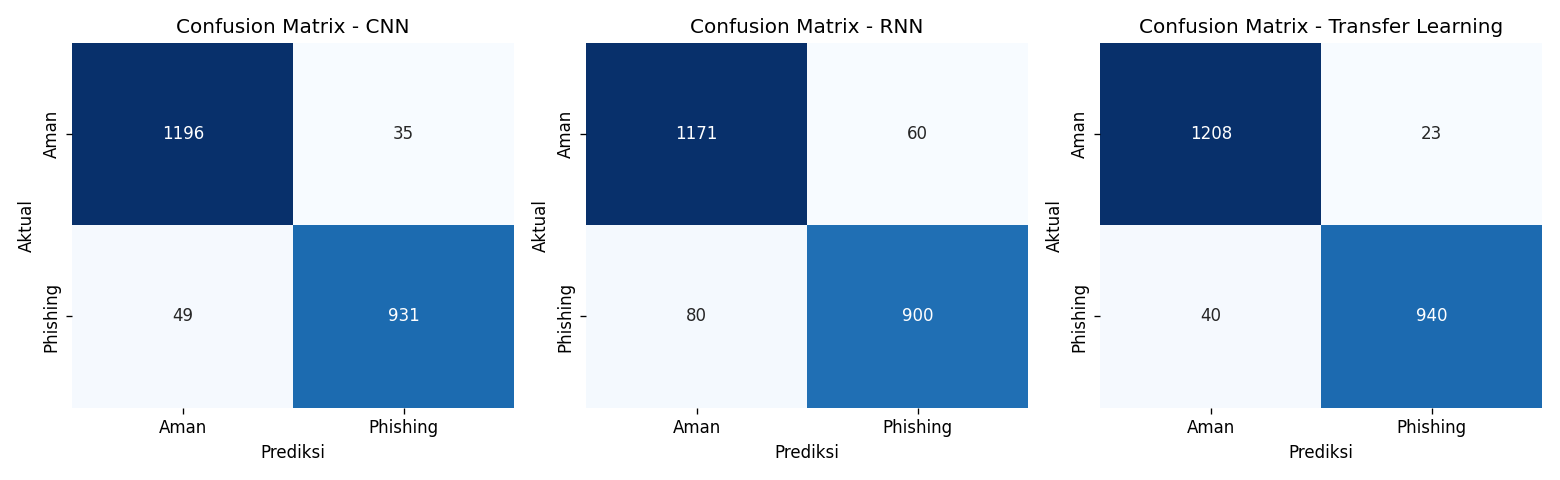

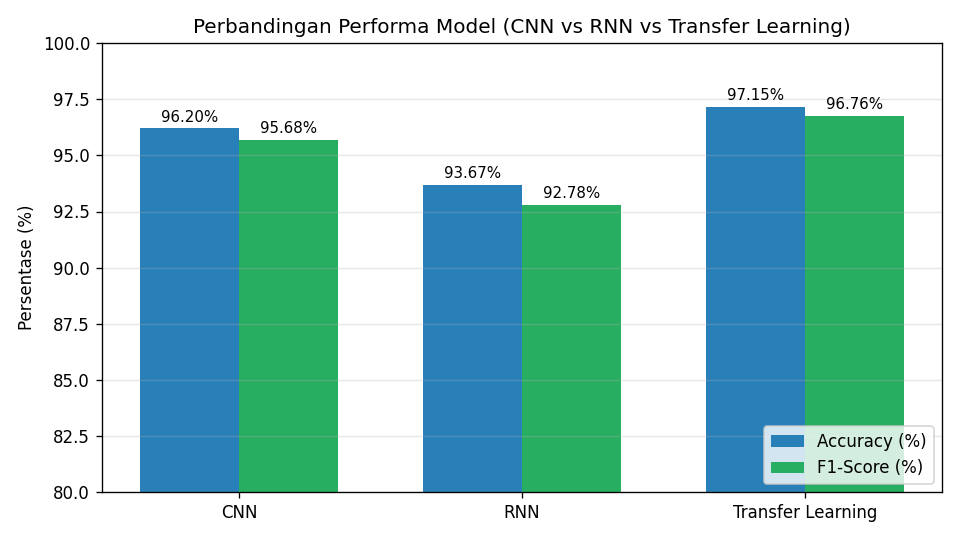

In [ ]:
# Visualisasi Grafik Accuracy & Loss, Confusion Matrix, dan Perbandingan Model
from IPython.display import Image, display
display(Image(filename='images/grafik_akurasi_loss.png'))
display(Image(filename='images/confusion_matrix.png'))
display(Image(filename='images/perbandingan_akurasi.png'))